In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


In [9]:
import boto3
import pandas as pd
from pathlib import PurePosixPath

# AWS configuration
BUCKET_NAME = "amal-stitchingnet-data-903473565738-ap-southeast-2-an"
REGION = "ap-southeast-2"
DATA_PREFIX = "data/"

# Connect to S3 using SageMaker execution role
s3 = boto3.client(
    "s3",
    region_name=REGION
)

print("Connected to S3")

# List all dataset objects
paginator = s3.get_paginator("list_objects_v2")

all_objects = []

for page in paginator.paginate(
    Bucket=BUCKET_NAME,
    Prefix=DATA_PREFIX
):
    all_objects.extend(
        page.get("Contents", [])
    )

print("Total objects:", len(all_objects))

# Rebuild inventory
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

records = []

for obj in all_objects:

    key = obj["Key"]

    if key.endswith("/"):
        continue

    path = PurePosixPath(key)

    folders = path.parts[1:-1]

    records.append({
        "file_name": path.name,
        "s3_key": key,
        "extension": path.suffix.lower(),
        "file_size_kb": obj["Size"] / 1024,
        "last_modified": obj["LastModified"],

        "folder_1": (
            folders[0] if len(folders) > 0 else None
        ),

        "folder_2": (
            folders[1] if len(folders) > 1 else None
        ),

        "is_image": (
            path.suffix.lower() in IMAGE_EXTENSIONS
        )
    })

inventory_df = pd.DataFrame(records)

# Recreate image dataframe
image_df = inventory_df[
    inventory_df["is_image"]
].copy()

# Recreate class distribution
class_distribution = (
    image_df.groupby("folder_2")
    .size()
    .reset_index(name="image_count")
)

class_distribution["class_id"] = (
    class_distribution["folder_2"]
    .str.extract(r"^(\d+)")
    .astype(int)
)

class_distribution = (
    class_distribution
    .sort_values("class_id")
    .reset_index(drop=True)
)

# Recreate fabric and class order
fabric_order = sorted(
    image_df["folder_1"].unique()
)

class_order = (
    class_distribution["folder_2"]
    .tolist()
)

# Select three images from each combination
combination_counts = (
    image_df.groupby(["folder_1", "folder_2"])
    .size()
)

assert combination_counts.min() >= 3, (
    "Some combinations have fewer than 3 images"
)

stratified_sample = (
    image_df
    .groupby(
        ["folder_1", "folder_2"],
        group_keys=False
    )
    .sample(
        n=3,
        random_state=42
    )
    .reset_index(drop=True)
)

# Verify everything
print("\nRECOVERY SUCCESSFUL")

print("Total images:", len(image_df))
print("Fabric categories:", len(fabric_order))
print("Stitching classes:", len(class_order))
print("Fabric/class combinations:", len(combination_counts))
print("Selected images:", len(stratified_sample))

display(
    stratified_sample[
        ["folder_1", "folder_2", "file_name"]
    ].head(15)
)

Connected to S3
Total objects: 14565

RECOVERY SUCCESSFUL
Total images: 14565
Fabric categories: 11
Stitching classes: 11
Fabric/class combinations: 121
Selected images: 363


,folder_1,folder_2,file_name
0,A. Cotton-Poly,0. Normal,A_00_133.jpg
1,A. Cotton-Poly,0. Normal,A_00_149.jpg
2,A. Cotton-Poly,0. Normal,A_00_094.jpg
3,A. Cotton-Poly,1. Skipped stitch,A_01_143.jpg
4,A. Cotton-Poly,1. Skipped stitch,A_01_115.jpg
5,A. Cotton-Poly,1. Skipped stitch,A_01_055.jpg
6,A. Cotton-Poly,10. Overlapped stitch,A_10_079.jpg
7,A. Cotton-Poly,10. Overlapped stitch,A_10_064.jpg
8,A. Cotton-Poly,10. Overlapped stitch,A_10_035.jpg
9,A. Cotton-Poly,2. Broken stitch,A_02_066.jpg


In [13]:
def load_stitching_image(filename):

    match = image_df[
        image_df["file_name"] == filename
    ]

    if len(match) == 0:
        raise ValueError(
            f"Image not found: {filename}"
        )

    key = match.iloc[0]["s3_key"]

    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    image = Image.open(
        BytesIO(response["Body"].read())
    ).convert("RGB")

    return np.array(image)


samples = {
    "Stain and damage": load_stitching_image(
        "F_07_014.jpg"
    ),

    "Needle mark": load_stitching_image(
        "K_08_011.jpg"
    ),

    "Puckering": load_stitching_image(
        "G_06_013.jpg"
    )
}

In [14]:
def create_image_variants(rgb):

    # Convert colour spaces
    lab = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2LAB
    )

    gray = cv2.cvtColor(
        rgb,
        cv2.COLOR_RGB2GRAY
    )

    # 1. Original
    original = rgb

    # 2. CLAHE on LAB lightness
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    lab_clahe = lab.copy()

    lab_clahe[:, :, 0] = clahe.apply(
        lab[:, :, 0]
    )

    clahe_rgb = cv2.cvtColor(
        lab_clahe,
        cv2.COLOR_LAB2RGB
    )

    # 3. Unsharp masking
    blurred = cv2.GaussianBlur(
        rgb,
        (0, 0),
        sigmaX=1.0
    )

    sharpened = cv2.addWeighted(
        rgb,
        1.5,
        blurred,
        -0.5,
        0
    )

    # 4. Sobel edge magnitude
    gx = cv2.Sobel(
        gray,
        cv2.CV_32F,
        1, 0,
        ksize=3
    )

    gy = cv2.Sobel(
        gray,
        cv2.CV_32F,
        0, 1,
        ksize=3
    )

    magnitude = cv2.magnitude(gx, gy)

    edges = cv2.normalize(
        magnitude,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)

    # 5. LAB A channel
    lab_a = cv2.normalize(
        lab[:, :, 1],
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # 6. LAB B channel
    lab_b = cv2.normalize(
        lab[:, :, 2],
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return {
        "Original": original,
        "CLAHE - Local contrast": clahe_rgb,
        "Unsharp masking": sharpened,
        "Sobel - Edge map": edges,
        "LAB - A channel": lab_a,
        "LAB - B channel": lab_b
    }

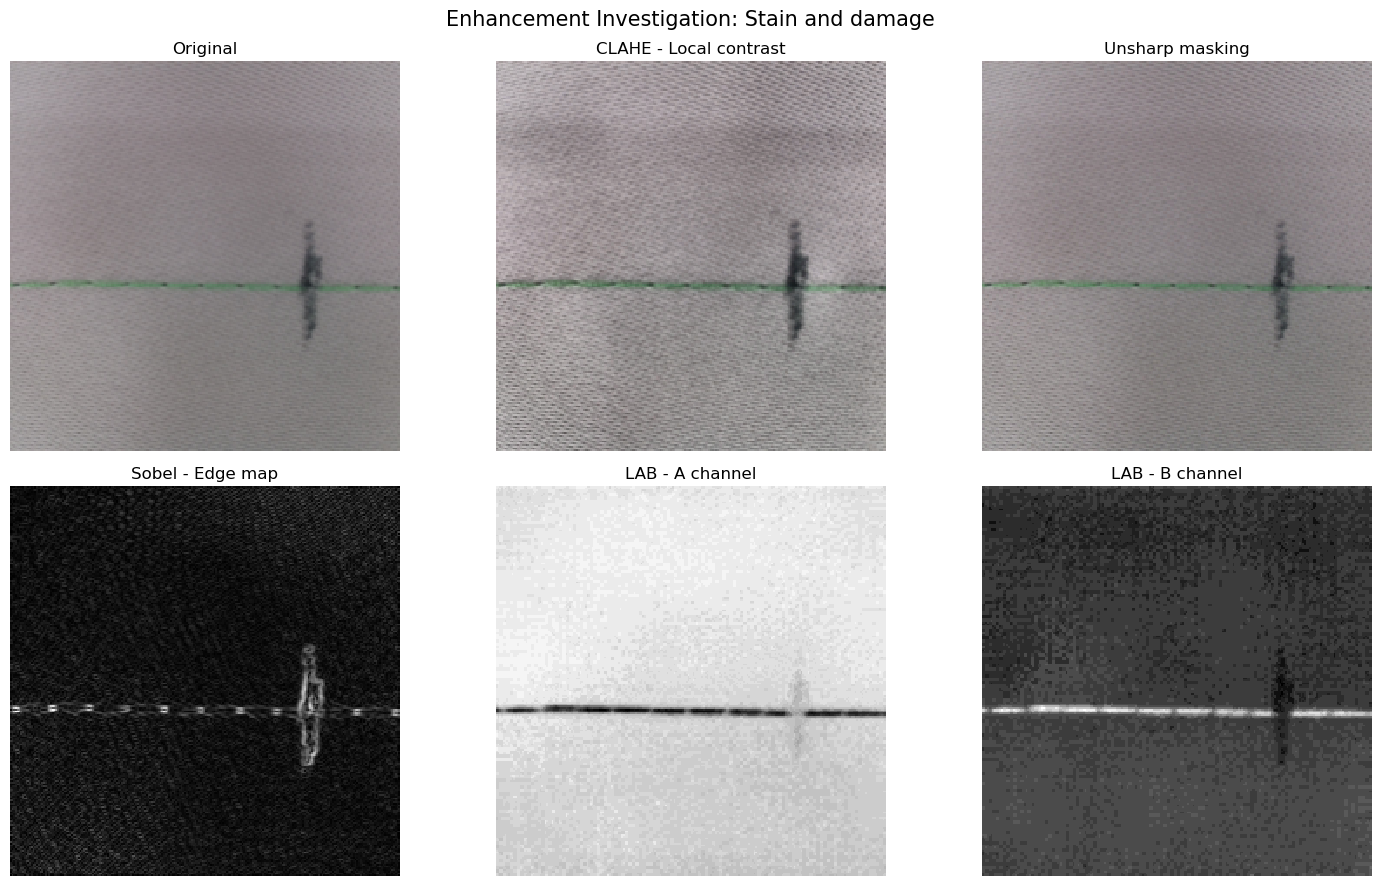

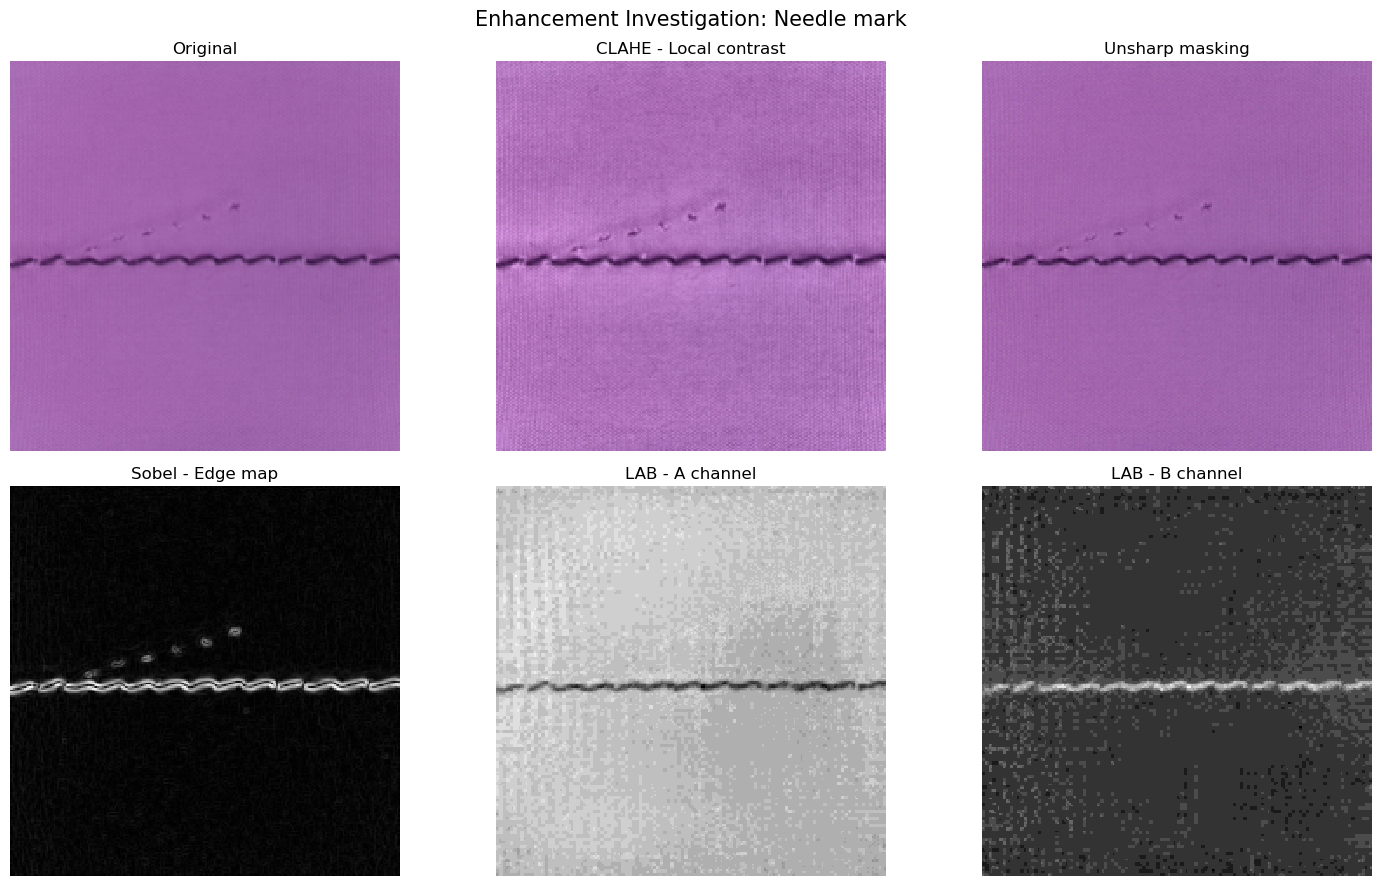

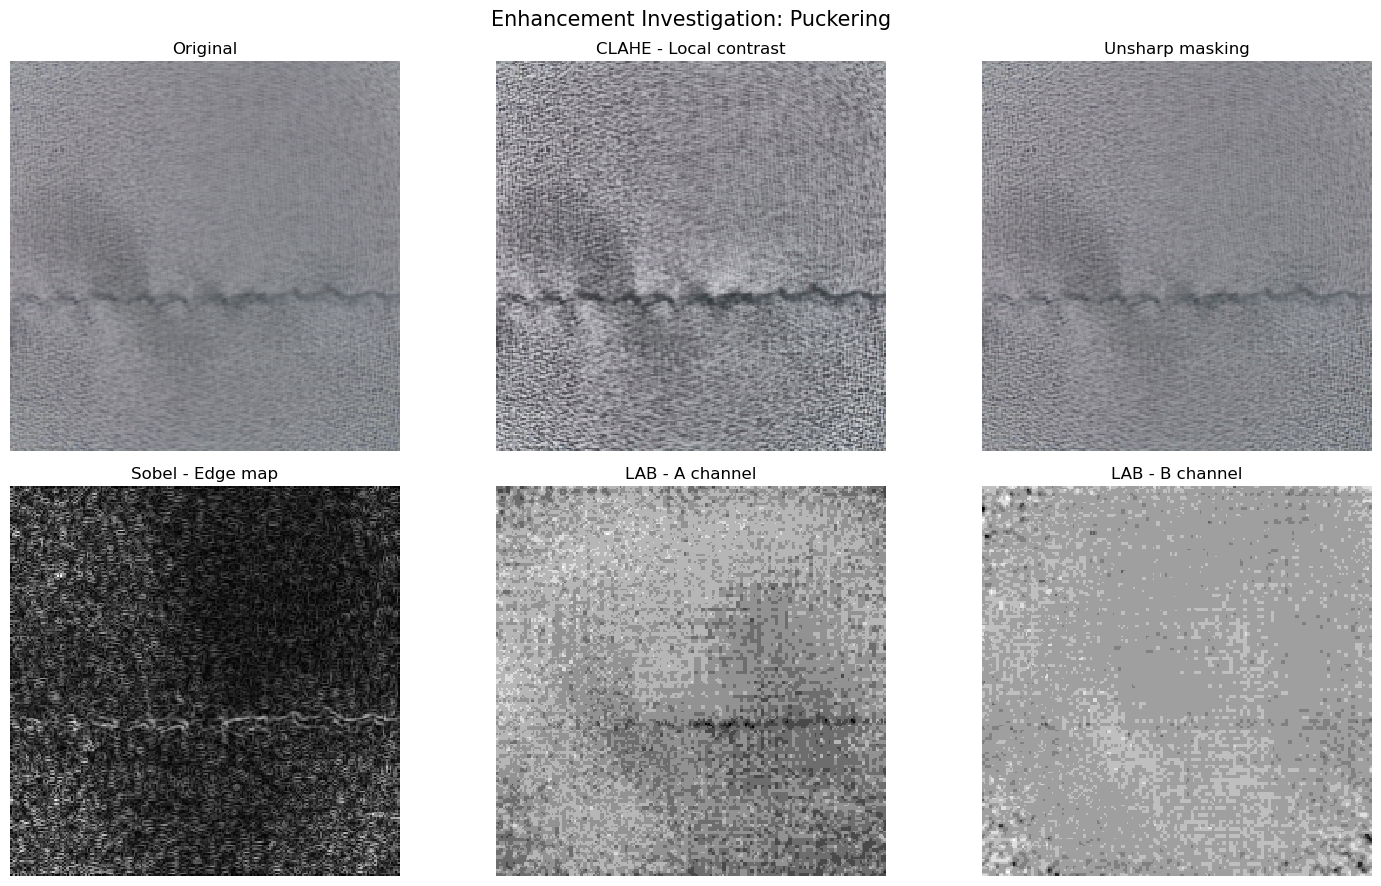

In [5]:
for class_name, image in samples.items():

    variants = create_image_variants(image)

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 9)
    )

    fig.suptitle(
        f"Enhancement Investigation: {class_name}",
        fontsize=15
    )

    for ax, (method, result) in zip(
        axes.flat,
        variants.items()
    ):

        ax.imshow(
            result,
            cmap="gray" if result.ndim == 2 else None,
            interpolation="nearest"
        )

        ax.set_title(method)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [15]:
from pathlib import Path

screening_sample = (
    image_df
    .groupby(
        ["folder_1", "folder_2"],
        group_keys=False
    )
    .sample(
        n=1,
        random_state=42
    )
    .sort_values(
        ["folder_2", "folder_1"]
    )
    .reset_index(drop=True)
)

assert len(screening_sample) == 121

output_dir = Path(
    "reports/eda/enhancement_experiments"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

screening_sample.to_csv(
    output_dir / "screening_121_images.csv",
    index=False
)

print("Selected images:", len(screening_sample))
print("Fabric categories:",
      screening_sample["folder_1"].nunique())
print("Defect categories:",
      screening_sample["folder_2"].nunique())

display(screening_sample.head(15))

Selected images: 121
Fabric categories: 11
Defect categories: 11


,file_name,s3_key,extension,file_size_kb,last_modified,folder_1,folder_2,is_image
0,A_00_133.jpg,data/A. Cotton-Poly/0. Normal/A_00_133.jpg,.jpg,68.052734,2026-11-02 23:13:12+00:00,A. Cotton-Poly,0. Normal,True
1,B_00_027.jpg,data/B. Linen-Poly/0. Normal/B_00_027.jpg,.jpg,72.565430,2026-11-02 22:37:21+00:00,B. Linen-Poly,0. Normal,True
2,C_00_008.jpg,data/C. Denim-Poly/0. Normal/C_00_008.jpg,.jpg,91.683594,2026-11-02 22:07:16+00:00,C. Denim-Poly,0. Normal,True
3,D_00_199.jpg,data/D. Velveteen-Poly/0. Normal/D_00_199.jpg,.jpg,64.891602,2026-11-02 21:43:47+00:00,D. Velveteen-Poly,0. Normal,True
4,E_00_167.jpg,data/E. Polyester-Poly/0. Normal/E_00_167.jpg,.jpg,60.408203,2026-11-02 21:17:04+00:00,E. Polyester-Poly,0. Normal,True
5,F_00_076.jpg,data/F. Satin-Core/0. Normal/F_00_076.jpg,.jpg,55.234375,2026-11-02 20:48:16+00:00,F. Satin-Core,0. Normal,True
6,G_00_164.jpg,data/G. Chiffon-Poly/0. Normal/G_00_164.jpg,.jpg,68.908203,2026-11-02 20:26:04+00:00,G. Chiffon-Poly,0. Normal,True
7,H_00_132.jpg,data/H. Nylon-Core/0. Normal/H_00_132.jpg,.jpg,58.119141,2026-11-02 20:02:24+00:00,H. Nylon-Core,0. Normal,True
8,I_00_014.jpg,data/I. Jacquard-Poly/0. Normal/I_00_014.jpg,.jpg,81.789062,2026-11-02 19:36:28+00:00,I. Jacquard-Poly,0. Normal,True
9,J_00_102.jpg,data/J. Oxford-Core/0. Normal/J_00_102.jpg,.jpg,67.760742,2026-11-02 19:14:14+00:00,J. Oxford-Core,0. Normal,True
